# KQC DaisyWoven — flip-chip indium-bump daisy-chain test chip (Quantcore PDK rebuild)

**What the chip is.** KQCircuits' `chips/daisy_woven.py` (class `DaisyWoven`, chip name "DC"; © IQM Finland Oy,
GPL-3.0, <https://github.com/iqm-finland/KQCircuits>; local copy
`other-libs/KQCircuits-main/.../kqcircuits/chips/daisy_woven.py`; the pattern is KQC's static cell
`elements/daisy_woven.oas`; spec `docs/designs/kqc/daisy_woven.md`). A process test for flip-chip bonding: the same
hand-drawn daisy-chain pattern on both faces (bottom chip `1t1`, top chip `2b1`) — Nb wiring, under-bump
metallization (UBM) and indium bumps — with probe pads around the edge and the number of bumps per chain written
next to each pad pair (2, 40, 80, 200, 2080). It is measured by DC resistance after bonding; there are no qubits,
resonators or RF lines.

This notebook **rebuilds** the chip on the Quantcore PDK — not a replica. We distribute the rebuild under
GPL-3.0. Most steps of a circuit notebook (launchers, routes, LOM, FEM, iterate) have nothing to act on here; each
says so.

| topic | KQC source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 10 × 10 mm, KQC `ChipFrame` on both faces | same 10 × 10 mm; the KQC chip cell is placed with `frames_enabled=[]`, so the Quantcore die frame (L dicing markers, 3 × 3 alignment grids, chip boundary, device ID "DC") replaces KQC's frame; the top chip gets no frame (PDK v3 defines none for it; its layers export to 800–804/0) |
| pattern | `DaisyWoven.build()`: the static pattern inverted over the chip box, UBM and indium bumps | the same KQC cell, so its own `build()` runs unchanged |
| pads | probe pads drawn in the static pattern | kept where the pattern has them (they are part of one static drawing, not pad instances; see step 4) |
| substrate | silicon (KQC simulation default) | sapphire 650 µm, εr 10.25 (it changes nothing here: there is no circuit to simulate) |
| junctions | none | none |
| cheese | none: `DaisyWoven` puts the whole chip box into `ground_grid_avoidance`, and the metal is only the pattern | **the original wins:** chip `cheese: "original"` — no PDK band |
| placement | the pattern fills the chip | the same (centred by construction) |

**Kept exactly:** the whole chip is the KQC `DaisyWoven` PCell placed once at the chip origin, so its `build()` runs
unchanged: the polarity inversion of the static pattern (chip box − pattern − existing avoidance →
`base_metal_gap_wo_grid`), the UBM (802/0 in the mask) and the indium bumps (801/0).

**Simplified / substituted:** nothing. Placing the KQC chip class as one cell imports the static pattern the KQC way.

## 1 · Setup

`LIVE` follows `QCC_LIVE` (default on: KLayout opens and redraws after every change; `QCC_LIVE=0` for batch
runs). `RUN_FEM = False` keeps the FEM step at "export only"; `True` solves the jobs in a new batch AEDT
2024 R1 (if installed). `FULL_FAB = False` skips the fab-only corner rounding in the fab step (`qcc mask` writes the full file).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
RUN_FEM = False                                  # True: solve the exported jobs in a new batch AEDT 2024 R1
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/kqc")                            # design JSON + final snapshots
STEPS = Path("build/snapshots/daisy_woven")  # step-by-step snapshots (build/ is not kept in the repo)

## 2 · The PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

This chip uses the frame, the flip-chip layers (800–804/0) and the fab layer map; it has no junctions, no
CPWs and no cheese.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## 3 · The die, its frame and the chip cell

`Designer(...)` starts the 10 × 10 mm chip with the name "DC" (the device ID). The chip cheese is `"original"`: the
source has none (its build puts the whole chip box into KQC's `ground_grid_avoidance`), so no PDK band is drawn.

The whole design is one instance: KQC's `DaisyWoven` chip PCell at the chip origin with `frames_enabled=[]`, so KQC
draws no `ChipFrame` on either face and the Designer chip draws the Quantcore die frame (L dicing markers on 1000/0,
3 × 3 alignment grids on 1001/0, the chip boundary on 100/0). Then the design is saved: `daisy_woven.json` is what
DRC, the fab export and `qcc` read.

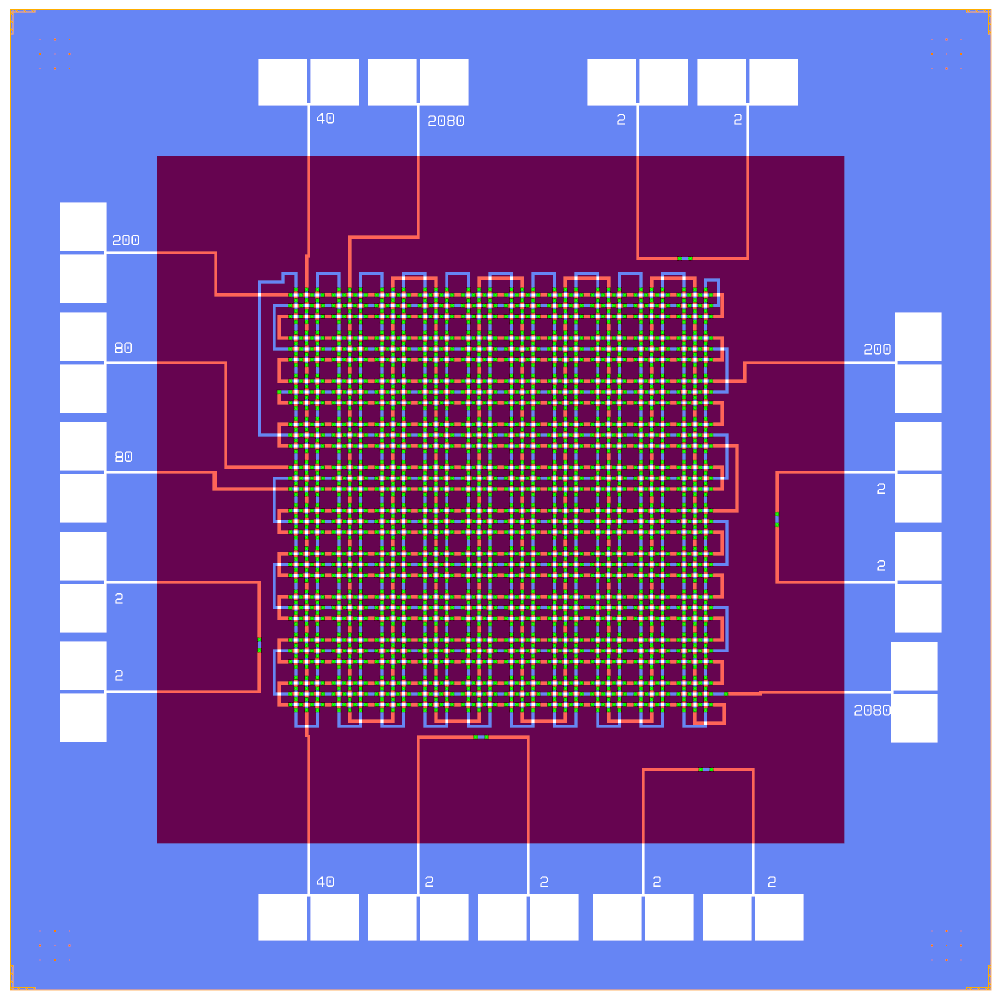

<Designer daisy_woven: 1 instances, 0 routes, live=False> → examples\designs\kqc\daisy_woven.json


In [4]:
d = Designer("daisy_woven", box=(0, 0, 10000, 10000), chip={"name_chip": "DC", "cheese": "original"}, live=LIVE)
d.add("DC", "DaisyWoven", at=(0, 0), frames_enabled=[])   # KQC chip PCell: static daisy pattern, UBM, indium bumps
snap(d, STEPS / "1_die.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420)
DESIGN = d.save(OUT / "daisy_woven.json")
print(d, "→", DESIGN)

## 4 · Pads and the pad rule

**PDK rule:** a bond pad's or launcher's outer etch edge sits `frame.pad_edge` (100 µm) from the die edge
(`edge="auto"` on a pad instance). This chip has no pad instances: its probe pads are part of KQC's static
pattern, one drawing with the chains and the bump counts, so the rule cannot move them without redrawing the
pattern, and the DRC's `pad_edge` check does not see them. The cell below measures where the pattern's metal
ends: the metal is what the inversion leaves unetched on the bottom face.

In [5]:
display(Markdown(pads_md(d)))
import klayout.db as kdb
rebuild(d)
ly = kdb.Layout()
ly.read(str(d.out))
top = ly.top_cell()


def layer_region(name):
    li = next((i for i in ly.layer_indexes() if ly.get_info(i).name == name), None)
    return kdb.Region() if li is None else kdb.Region(top.begin_shapes_rec(li)).merged()


x0, y0, x1, y1 = d.design.chip.box
die = kdb.Region(kdb.DBox(x0, y0, x1, y1).to_itype(ly.dbu))
metal = die - layer_region("1t1_base_metal_gap_wo_grid")   # what the inversion leaves unetched (bottom face)
mb = metal.bbox().to_dtype(ly.dbu)
print(f"bottom-face metal spans ({mb.left:.0f}, {mb.bottom:.0f}) – ({mb.right:.0f}, {mb.top:.0f}) µm: "
      f"{min(mb.left - x0, mb.bottom - y0, x1 - mb.right, y1 - mb.top):.0f} µm from the nearest die edge")

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| – | no bond pads or launchers | – | – | – |

bottom-face metal spans (500, 500) – (9499, 9500) µm: 500 µm from the nearest die edge


**Here:** no pad instances. The bottom-face metal (chains and probe pads) spans (500, 500) – (9500, 9500) µm: the static pattern keeps a 500 µm border, so its outer probe pads end 500 µm from the die edge, 400 µm further in than the rule's 100 µm. They are left there (moving them means redrawing the pattern); the DRC raises no `pad_edge` warning because they are not pad instances.

## 5 · Components

The one component is the `DaisyWoven` chip cell itself (placed in step 3). It has no parameters of its own beyond
the KQC `Chip` ones; everything it draws comes from the static pattern.

## 6 · Routes

None: the daisy chains are drawn in the static pattern, and there are no RF lines to route.

## 7 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to read. **PDK
design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged,
never enforced — the rebuild keeps the source's choices. `pdk_report` adds the cheese source, the centring
and the junction types.

**Here:** 0 errors and 9 warnings, all from the frame: `frame_keepout` × 8 (the `DC` cell overlaps the corner marker areas) and `frame_margin` × 1 (it reaches into the 100 µm die margin). They are real: `DaisyWoven` inverts its pattern over the whole chip box, so the base etch 1/0 also covers the die corners under the PDK markers (1000/0 and 1001/0 are their own fab layers; the frame-corner snapshot shows it). A fab version would stop the inversion at the design area. No PDK design warning; `pdk_report` gives no cheese ("the original design's own (or none)"), the content centred (0, 0) and no junctions.

In [6]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

**0 errors · 9 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `frame_keepout` | 8 | DC overlaps the marker_area_sw |
| warning | `frame_margin` | 1 | DC reaches into the 100 µm die margin (dicing markers) |

| check | value |
|---|---|
| cheese | the original design's own (or none) |
| content centre − die centre | (+0, +0) µm |
| junction types | — |
| PDK design warnings | 0 (none) |

## 8 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit from the components' LOM models. No component here has one (the
daisy chains are DC test structures), so the netlist is ground only.

In [7]:
lb = d.lom()
show_netlist(lb)
print(lom_summary(lb))

**1 nodes · 0 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |

| branch | type | nodes | estimate |
|---|---|---|---|

**Unconnected ports:** none

{'nodes': 0, 'branches': 0, 'controls': 0, 'unconnected': 0}


## 9 · LOM simulation — not applicable; the test-structure summary instead

There are no modes to simulate. What this chip measures is the resistance of each bump chain, so the useful
numbers are the bump and UBM counts per face, from the built layout (one indium bump on each UBM pad; the two
faces carry the same pattern, so the bumps meet when the top chip is flipped on).

In [8]:
rows = ["| face | indium bumps | UBM pads | bump size (µm) | etched area (mm²) |", "|---|---|---|---|---|"]
for face in ("1t1", "2b1"):
    bumps, ubm = layer_region(f"{face}_indium_bump"), layer_region(f"{face}_underbump_metallization")
    gap = layer_region(f"{face}_base_metal_gap_wo_grid")
    b0 = next(iter(bumps.each())).bbox() if bumps.count() else None
    size = f"{b0.width() * ly.dbu:.0f} × {b0.height() * ly.dbu:.0f}" if b0 else "–"
    rows.append(f"| {face} | {bumps.count()} | {ubm.count()} | {size} | {gap.area() * ly.dbu ** 2 / 1e6:.2f} |")
display(Markdown("\n".join(rows)))

| face | indium bumps | UBM pads | bump size (µm) | etched area (mm²) |
|---|---|---|---|---|
| 1t1 | 2412 | 2412 | 24 × 24 | 82.31 |
| 2b1 | 2412 | 2412 | 24 × 24 | 41.10 |

**Here:** 2412 indium bumps on 2412 UBM pads per face, 24 × 24 µm each. The base etch covers 82.31 mm² of the bottom chip and 41.10 mm² of the top chip (the top chip is the inner ≈ 7 × 7 mm).

## 10 · FEM: send the jobs

One job per sim group and analysis: the group is cut out of the chip with its margin, every line leaving the
box ends in a port, junctions are lumped ports, and the ground grid is removed (simulation exports never have
cheese). The table lists each job's ports and C-matrix nets (named after islands, couplers and routes, so the
result maps back onto the LOM nodes).

With `RUN_FEM = True` and AEDT 2024 R1 (or later) installed, `send_fem_jobs` solves each Ansys job in a **new
batch, non-graphical** AEDT (`solve_job`) — an AEDT window you have open is never touched. The command-line
equivalent is `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

Here: nothing to export: the chip has no sim groups (a DC daisy-chain test has nothing for a C-matrix or
eigenmode solve), so `send_fem_jobs` writes no job.

In [9]:
jobs = send_fem_jobs(DESIGN, run=RUN_FEM)
display(Markdown(jobs_md(jobs) if jobs else "No sim groups: no FEM job."))

0 job(s) exported; RUN_FEM is False, nothing solved.


No sim groups: no FEM job.

## 11 · Bring the results back

When a job has been solved its folder holds `results/results.json`. `fem_back` then calls
`fill(model, design, job)`: the C-matrix (or eigenmode) values replace the component estimates branch by
branch (matched by net name), and the table compares the two. `simulate(filled)` re-runs the LOM on the
extracted values. Until then the cell says which jobs are still waiting.

In [10]:
filled, md = fem_back(lb.model, DESIGN, jobs)
display(Markdown(md or "No FEM jobs."))
if filled:
    from quantcore_circuits.lom.simulate import simulate
    key, fc = next(iter(filled.items()))
    display(Markdown(f"**LOM on the FEM values ({key}):**\n\n" + modes_md(simulate(fc, max_modes=2))))

No FEM jobs.

## 12 · Change one property — not applicable

`DaisyWoven` has no parameters of its own (the pattern is a static file) and there is no simulation to re-run, so
this step has nothing to change. A variant would be a new static pattern.

## 13 · Build and export

**The design file.** `daisy_woven.json` (saved in step 3) is the whole design: `qcc build
examples/designs/kqc/daisy_woven.json` rebuilds `build/daisy_woven.oas` + its sidecar, and the KLayout plugin,
`qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the filled 3/0 keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese
hole), no junction layers (there are none),
and the frame (100/0, 1000/0, 1001/0). The cheese source is `original` with no holes: the source has no cheese, and none is added. The
top chip's etch (face 2b1) goes to 800/0; the indium bumps and the UBM of both faces go to 801/0 and
802/0 (the PDK collects both faces there; the two patterns coincide). In this run: 1/0 23 polygons, 3/0 1 (the keep-out covers the whole etched area), 800/0 1, 801/0 and 802/0 2412 each, 100/0 1, 1000/0 4, 1001/0 36; cheese source `original`, 0 holes. Corner rounding (fab only) is skipped unless `FULL_FAB`;
`qcc mask examples/designs/kqc/daisy_woven.json` writes the complete file.

In [11]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 23 |
| 3/0 | M3 | 1 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 800/0 | FC_M1 | 1 |
| 801/0 | FC_BUMPS | 2412 |
| 802/0 | FC_UBM | 2412 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `original`, 0 holes on the mask.

→ `build/daisy_woven_fab.oas`

## 14 · Snapshots

The full chip (bottom face blue, top face red); a zoom on the bump array and one daisy-chain corner; the die frame's
south-west corner (dicing L on 1000/0, 3 × 3 alignment grid on 1001/0); the bump array in the **fab view** (the mask
from step 13). The chip boundary 100/0 is drawn as an outline.

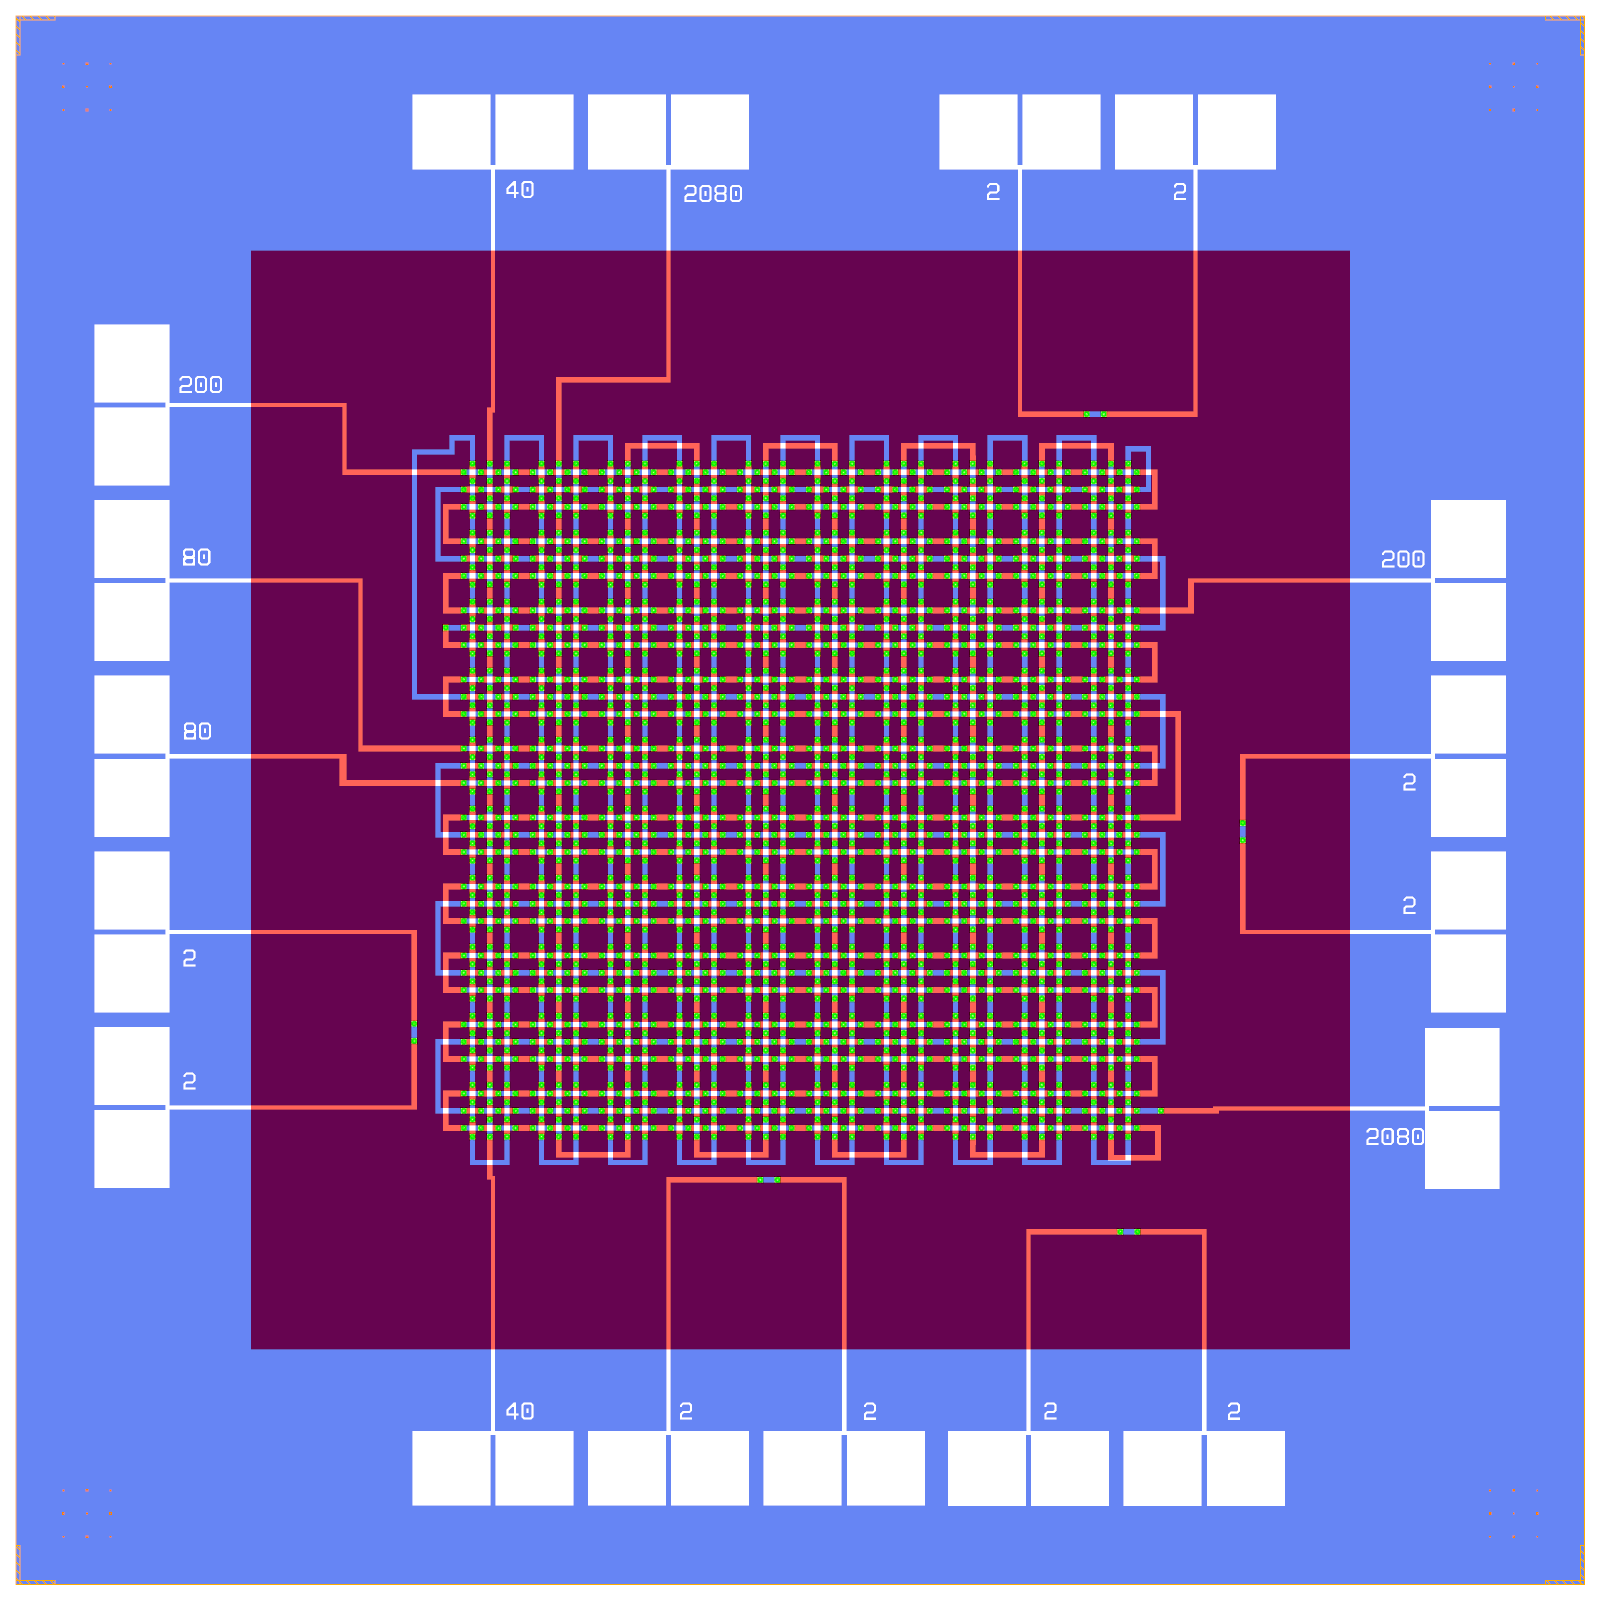

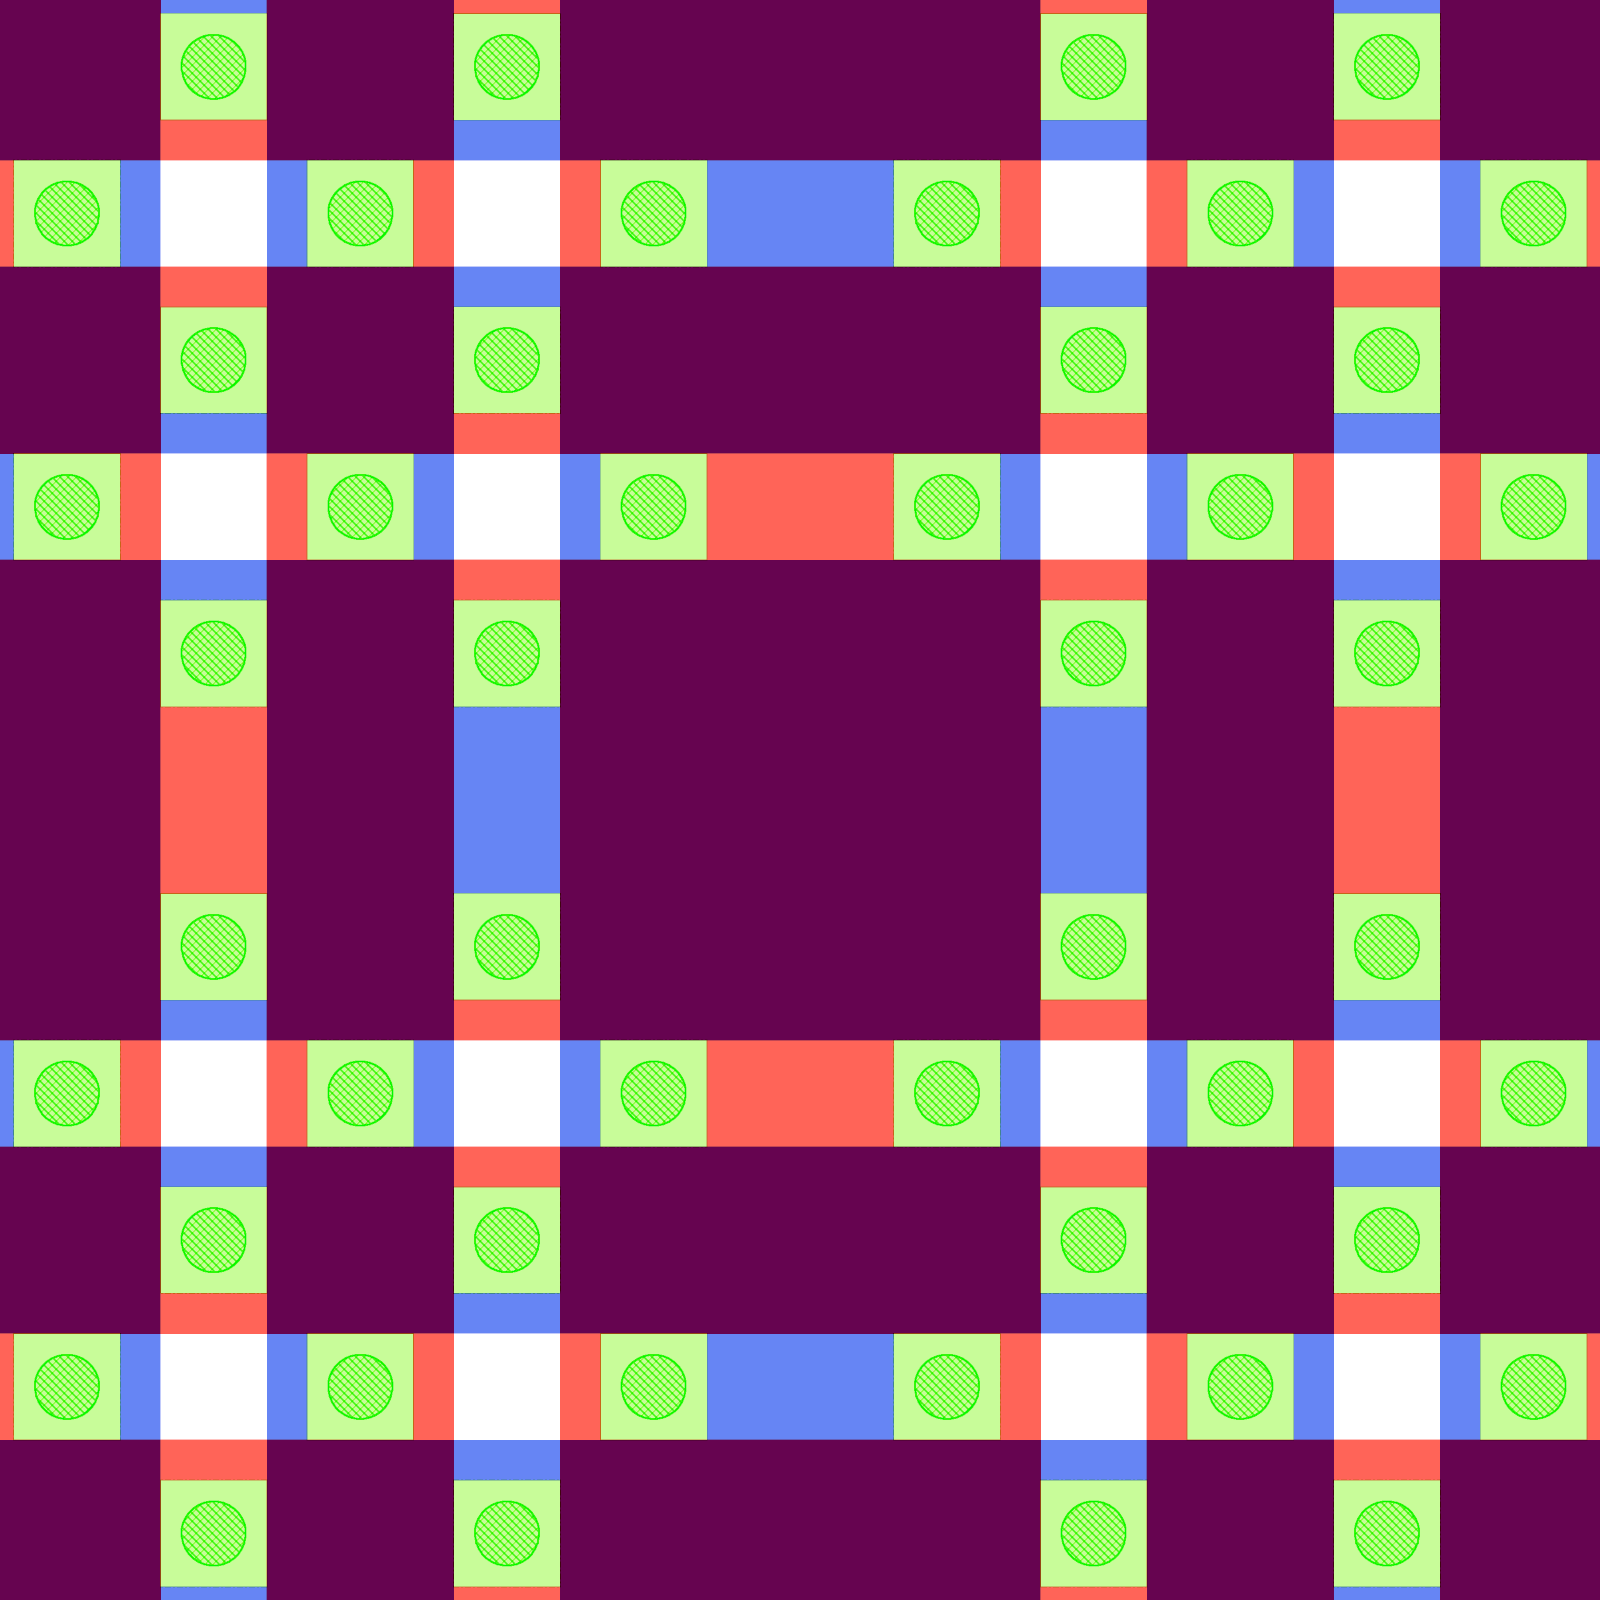

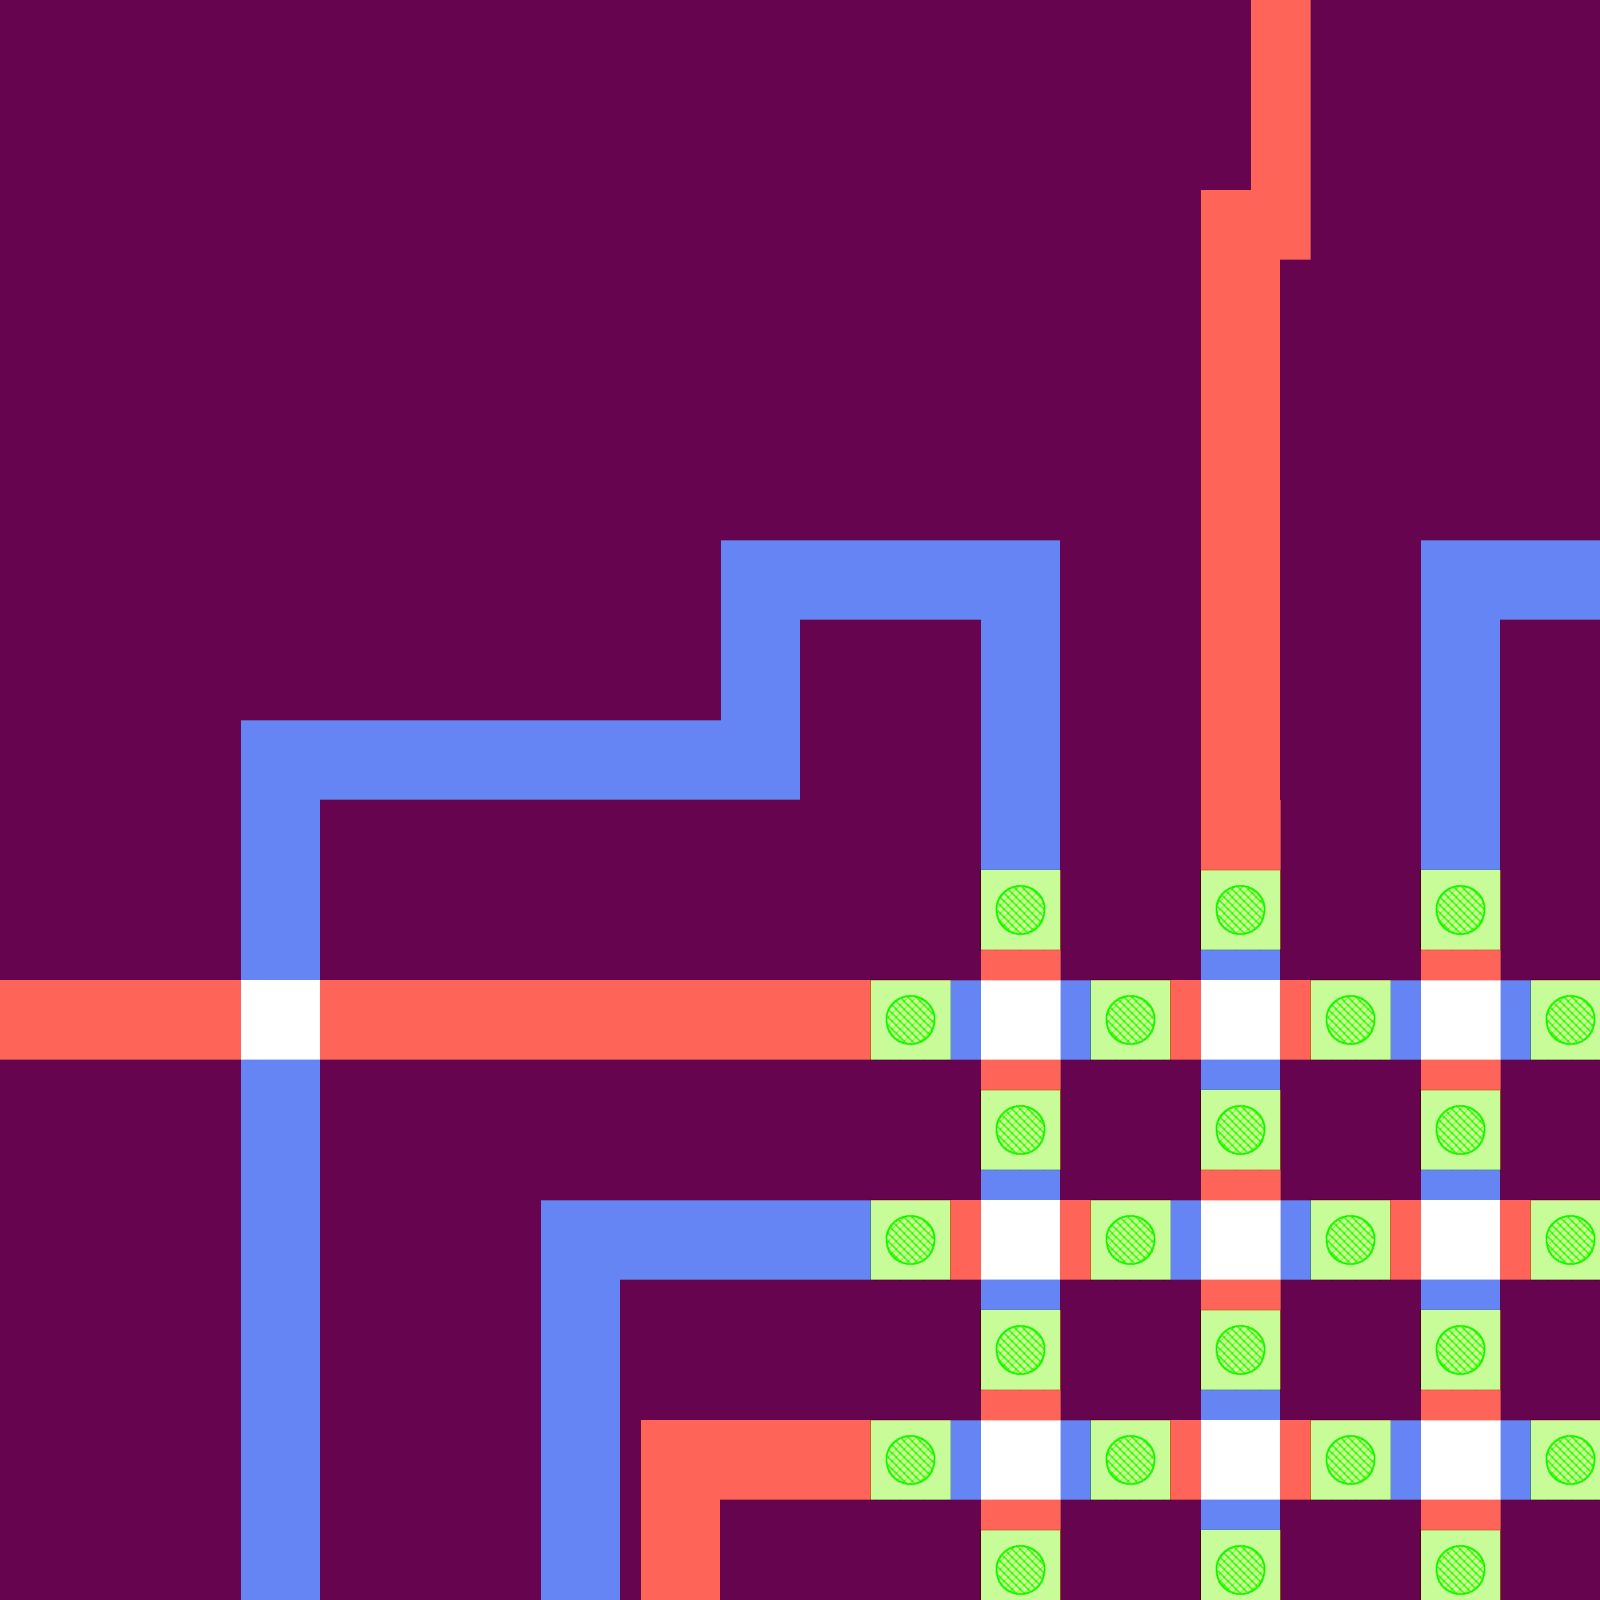

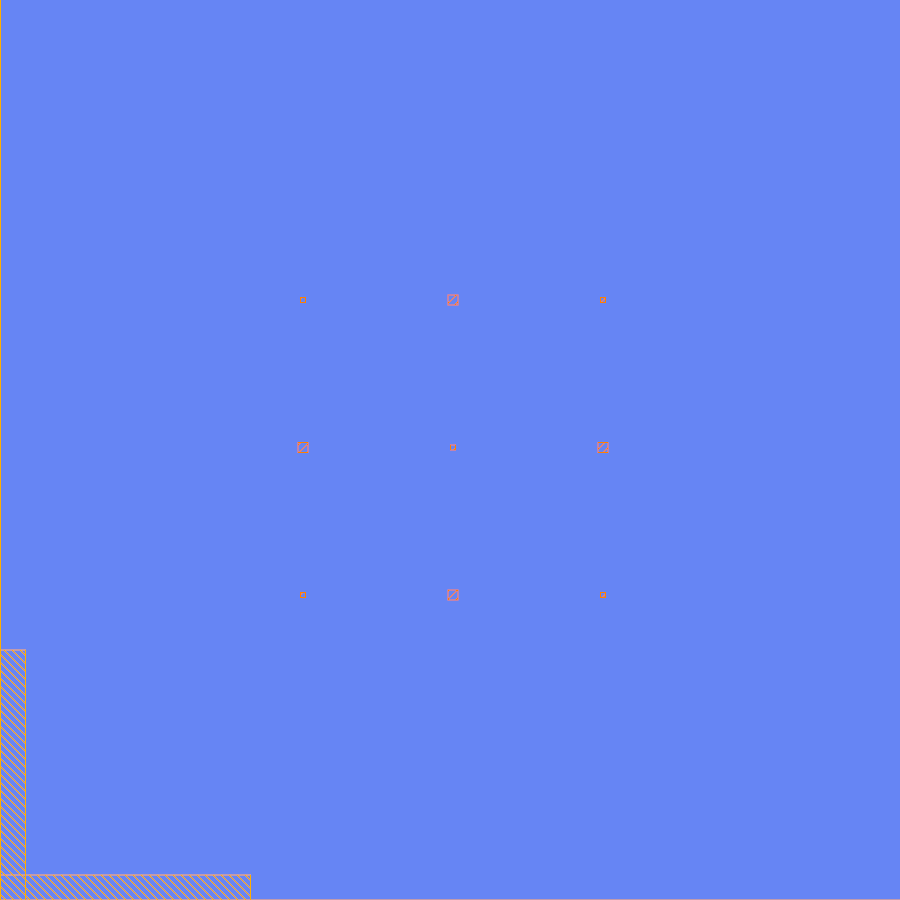

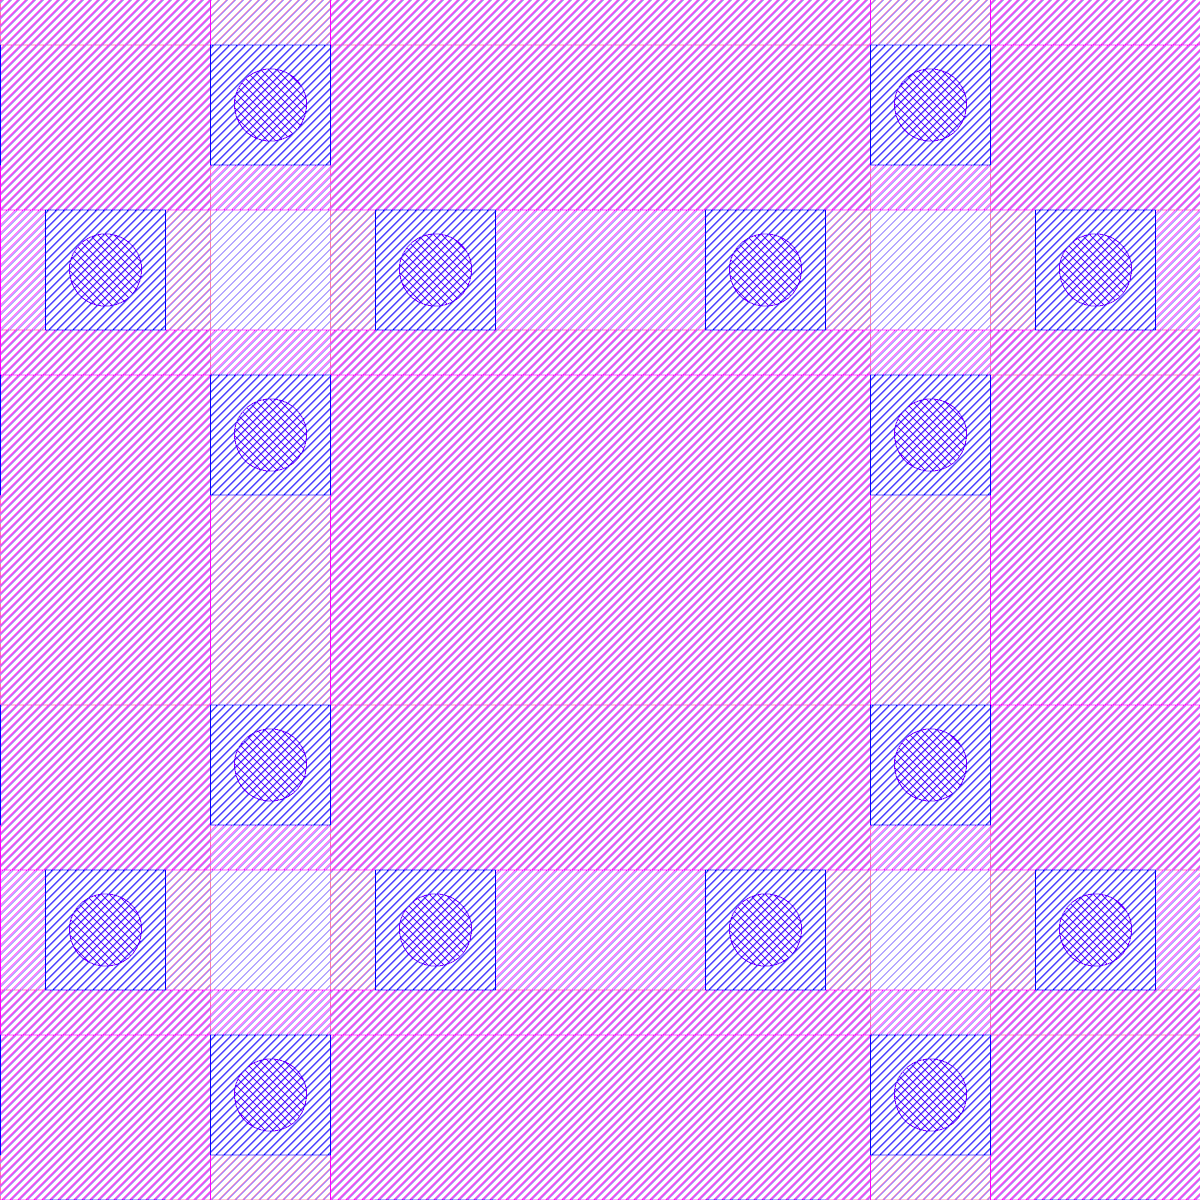

In [12]:
show_snapshot(d, OUT / "daisy_woven.png")
show_snapshot(d, OUT / "daisy_woven_bumps.png", box=(4700, 4700, 5300, 5300), width=420)
show_snapshot(d, OUT / "daisy_woven_corner.png", box=(2400, 6800, 3200, 7600), width=420)
show_snapshot(d, OUT / "daisy_woven_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "daisy_woven_fab.oas", OUT / "daisy_woven_fab_bumps.png", box=(4800, 4800, 5200, 5200),
          size=(1200, 1200), width=420);   # fab view

**Reference: XOR with the source.** KQC's `DaisyWoven` built stand-alone (with KQC's own frames), XOR-ed layer by
layer with this build (`refpoints` skipped). **The rebuild is expected to differ** by design in the frame (KQC's
ChipFrame on both faces vs the Quantcore die frame on the bottom chip); the pattern, UBM and bump layers should
agree. A reference, not a pass/fail check.

| layer | XOR area (µm²) |
|---|---|
| 1t1_ground_grid_avoidance (133/1) | 2e+05 |
| 1t1_base_metal_gap_wo_grid (130/1) | 6.14e+06 |
| 1t1_underbump_metallization (148/1) | 0 |
| 1t1_indium_bump (149/1) | 0 |
| 2b1_ground_grid_avoidance (5/2) | 1.4e+05 |
| 2b1_base_metal_gap_wo_grid (2/2) | 4.54e+06 |
| 2b1_underbump_metallization (20/2) | 0 |
| 2b1_indium_bump (21/2) | 0 |
| 1t1_base_metal_gap_for_EBL (134/1) | 8.53e+06 |
| 1t1_chip_dicing (158/1) | 2.68e+05 |
| 1t1_airbridge_pads (146/1) | 5.4e+05 |
| 1t1_airbridge_flyover (147/1) | 2.81e+05 |
| 2b1_base_metal_gap_for_EBL (6/2) | 4.52e+06 |
| 2b1_chip_dicing (30/2) | 1.88e+05 |
| 2b1_airbridge_pads (18/2) | 5.21e+05 |
| 2b1_airbridge_flyover (19/2) | 2.62e+05 |

**Total XOR area: 2.61e+07 µm²**

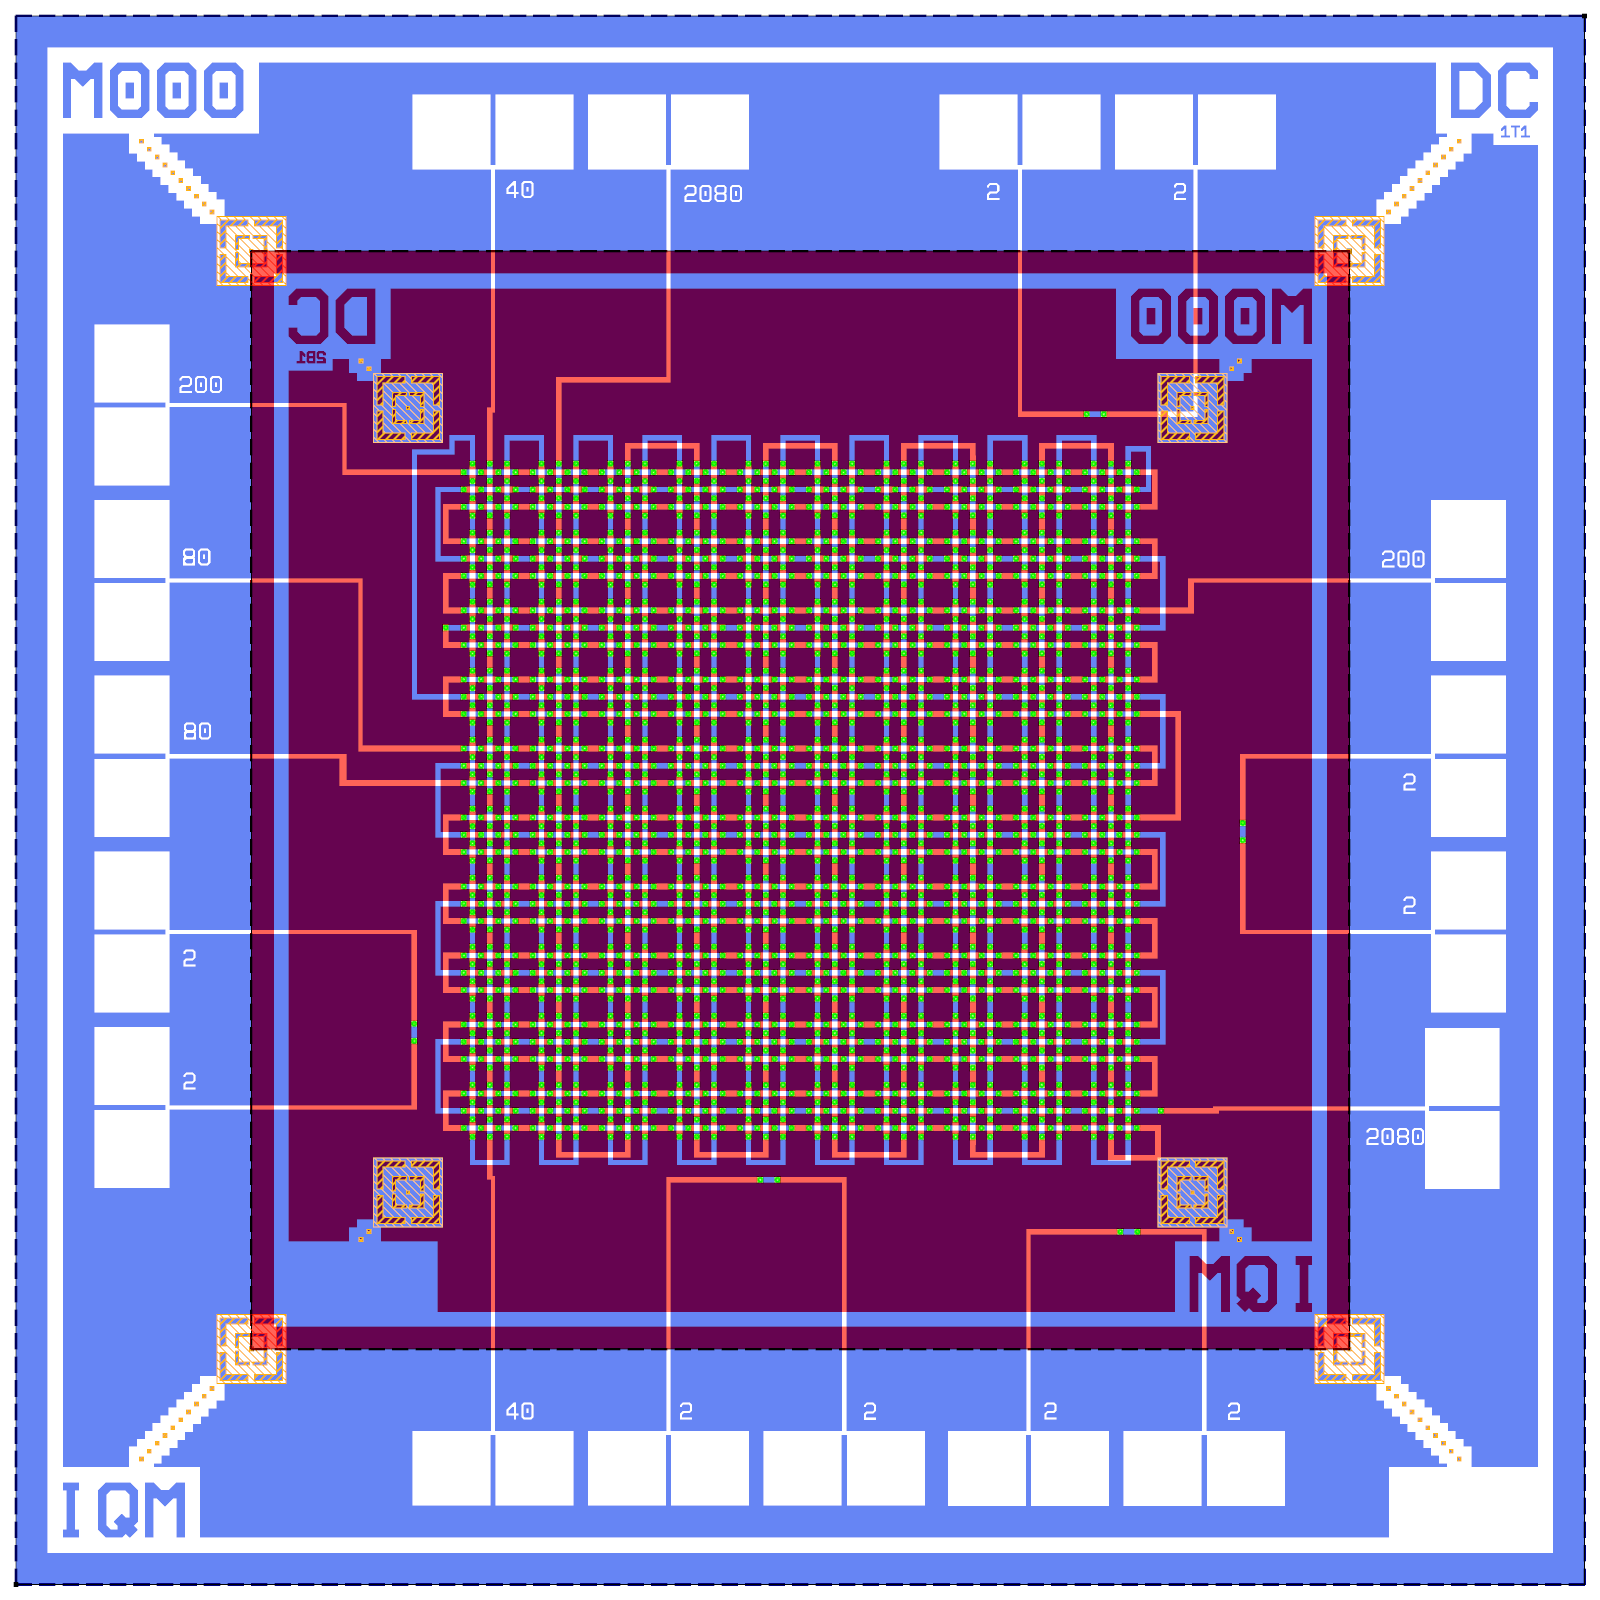

In [13]:
from kqcircuits.chips.daisy_woven import DaisyWoven
from kqcircuits.pya_resolver import pya

ref = pya.Layout()
ref_top = ref.create_cell("ref")
ref_top.insert(pya.DCellInstArray(DaisyWoven.create(ref).cell_index(), pya.DTrans()))
ref.write(str(Path("build") / "daisy_woven_kqc_original.oas"))
xor_rows, total = ["| layer | XOR area (µm²) |", "|---|---|"], 0.0
for li in ref.layer_indexes():
    info = ref.get_info(li)
    a = kdb.Region(ref_top.begin_shapes_rec(li)).merged()
    if a.is_empty() or info.name in ("refpoints",):
        continue
    b = layer_region(info.name)
    x = (a ^ b).area() * ref.dbu ** 2
    total += x
    xor_rows.append(f"| {info.name} ({info.layer}/{info.datatype}) | {x:.3g} |")
display(Markdown("\n".join(xor_rows) + f"\n\n**Total XOR area: {total:.3g} µm²**"))
snap_file(Path("build") / "daisy_woven_kqc_original.oas", OUT / "daisy_woven_kqc.png", box=(-100, -100, 10100, 10100),
          width=420);

**Here:** the UBM and indium-bump layers agree exactly (XOR 0) on both faces. The base etch differs by 6.14 mm² (bottom) and 4.54 mm² (top), and KQC's build has EBL, airbridge-pad and dicing-edge shapes this one lacks: KQC's frames (dicing edge, corner markers and chip labels, with their avoidance areas, which the inversion leaves unetched) are not drawn here.

## 15 · Summary

| | |
|---|---|
| **matches the source** | the whole `DaisyWoven` cell (KQC's own `build()`): the inverted static pattern, UBM and indium bumps on both faces; no cheese, as in the source |
| **differs (PDK)** | the Quantcore die frame instead of KQC's ChipFrame (bottom chip; none on the top chip); the PDK fab layer map (1/0, 800–802/0, 1000/0, 1001/0, 100/0) |
| **not applicable** | launchers and the pad rule (the probe pads are in the static pattern), routes, LOM, FEM, the iterate step |
| **PDK design warnings** | as listed in step 7 |
| **FEM** | no sim groups, no jobs |